# P-1 comparison: ARX vs Random Forest (5 lags) vs saved LSTM

A separate comparison notebook based on the figures and tables in Juan's comparison notebook. **Run the ARX and RF export cells first** (provided in the two `_with_export.ipynb` copies). This notebook **does not refit** those models.

For all three models: original P-1 test indices, 250-history/10-step tail alignment, and the shared `detection.py` anomaly detector. The LSTM is evaluated from its saved forecasts, not re-trained.

**Cost scope:** ARX and RF complete-pipeline runtime and illustrative cloud cost only. Saved LSTM forecasts are insufficient to benchmark LSTM inference cost; no LSTM cost estimate is fabricated.

In [18]:
from pathlib import Path
import sys, ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd().resolve()
repo_dir = next((d for d in (cwd, *cwd.parents) if (d / "detection.py").is_file() and (d / "data/data/test/P-1.npy").is_file()), None)
if repo_dir is None:
    raise FileNotFoundError("Run from your spacecraft repository root or its Models folder.")
sys.path.insert(0, str(repo_dir))
import detection

data_dir = repo_dir / "data" / "data"
results_dir = repo_dir / "results" / "hodaj_p1_model_comparison"
results_dir.mkdir(parents=True, exist_ok=True)
test = np.load(data_dir / "test" / "P-1.npy")
labels = pd.read_csv(data_dir / "labeled_anomalies.csv")
rows = labels.loc[labels["chan_id"] == "P-1"]
if rows.empty: raise ValueError("P-1 labels not found")
events = sorted({(int(a), int(b)) for entry in rows["anomaly_sequences"] for a,b in ast.literal_eval(entry)})
print("Repository:", repo_dir)
print("Ground truth P-1 events:", events)

Repository: /Users/jezercahodaj/Desktop/Erdos-Project/fall-2026-spacecraft-sensors
Ground truth P-1 events: [(2149, 2349), (3539, 3779), (4536, 4844)]


## Load ARX and RF results saved by the two modeling notebooks

In [19]:
files = {"ARX": results_dir / "arx_results.npz", "RF(5)": results_dir / "rf5_results.npz"}
models = {}
for name, path in files.items():
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}. Run the last export cell in the corresponding _with_export notebook.")
    with np.load(path) as z:
        models[name] = {key: z[key].copy() for key in z.files}

indices = models["ARX"]["indices"]
assert np.array_equal(indices, models["RF(5)"]["indices"]), "ARX and RF time indices differ"
assert np.array_equal(indices, np.arange(250, len(test)-10)), "Unexpected index alignment"
actual = test[indices, 0]
for name, result in models.items():
    assert len(result["predictions"]) == len(indices)
    assert len(result["raw_errors"]) == len(indices)
    assert len(result["smoothed_errors"]) == len(indices)
    print(name, "predictions:", len(result["predictions"]), "alerts:", len(result["detected_intervals"]))

ARX predictions: 8245 alerts: 1
RF(5) predictions: 8245 alerts: 2


## Load the authors’ saved LSTM forecasts and apply the *same* detector

In [20]:
run_name = "2018-05-19_15.00.10"
lstm_path = data_dir / run_name / "y_hat" / "P-1.npy"
if not lstm_path.is_file():
    matches = list(repo_dir.rglob(f"{run_name}/y_hat/P-1.npy"))
    if len(matches) != 1:
        raise FileNotFoundError(f"Cannot uniquely locate saved LSTM predictions: {matches}")
    lstm_path = matches[0]
lstm_predictions = np.load(lstm_path).reshape(-1)
assert len(lstm_predictions) == len(indices), (len(lstm_predictions), len(indices))
settings = dict(history_length=250, n_predictions=10, target_column=0,
                batch_size=70, window_size=30, smoothing_perc=0.05,
                error_buffer=100, p=0.13, initial_adjustment=True, initial_ignore=500)
lstm_detection = detection.detect_anomalies(test_data=test, predictions=lstm_predictions, **settings)
assert np.array_equal(lstm_detection["prediction_indices"], indices)
models["Saved LSTM"] = {
    "indices": indices, "predictions": lstm_predictions,
    "detected_intervals": np.asarray(lstm_detection["detected_intervals"], dtype=int).reshape(-1,2),
    "raw_errors": np.asarray(lstm_detection["raw_errors"], dtype=float).reshape(-1),
    "smoothed_errors": np.asarray(lstm_detection["smoothed_errors"], dtype=float).reshape(-1),
}
print("LSTM source:", lstm_path)
print("LSTM alerts:", len(models["Saved LSTM"]["detected_intervals"]))

LSTM source: /Users/jezercahodaj/Desktop/Erdos-Project/fall-2026-spacecraft-sensors/data/data/2018-05-19_15.00.10/y_hat/P-1.npy
LSTM alerts: 4


## Forecasting accuracy on the same 8,245 targets

In [21]:
accuracy = pd.DataFrame([
    {"Model": name, "MAE": np.mean(np.abs(actual - result["predictions"])),
     "RMSE": np.sqrt(np.mean((actual - result["predictions"])**2))}
    for name, result in models.items()
]).set_index("Model")
display(accuracy)
accuracy.to_csv(results_dir / "forecast_accuracy.csv")

,MAE,RMSE
Model,,
ARX,0.125347,0.194170
RF(5),0.099186,0.154960
Saved LSTM,0.170085,0.216681


## Actual vs predicted telemetry: full series and zooms for each labeled event

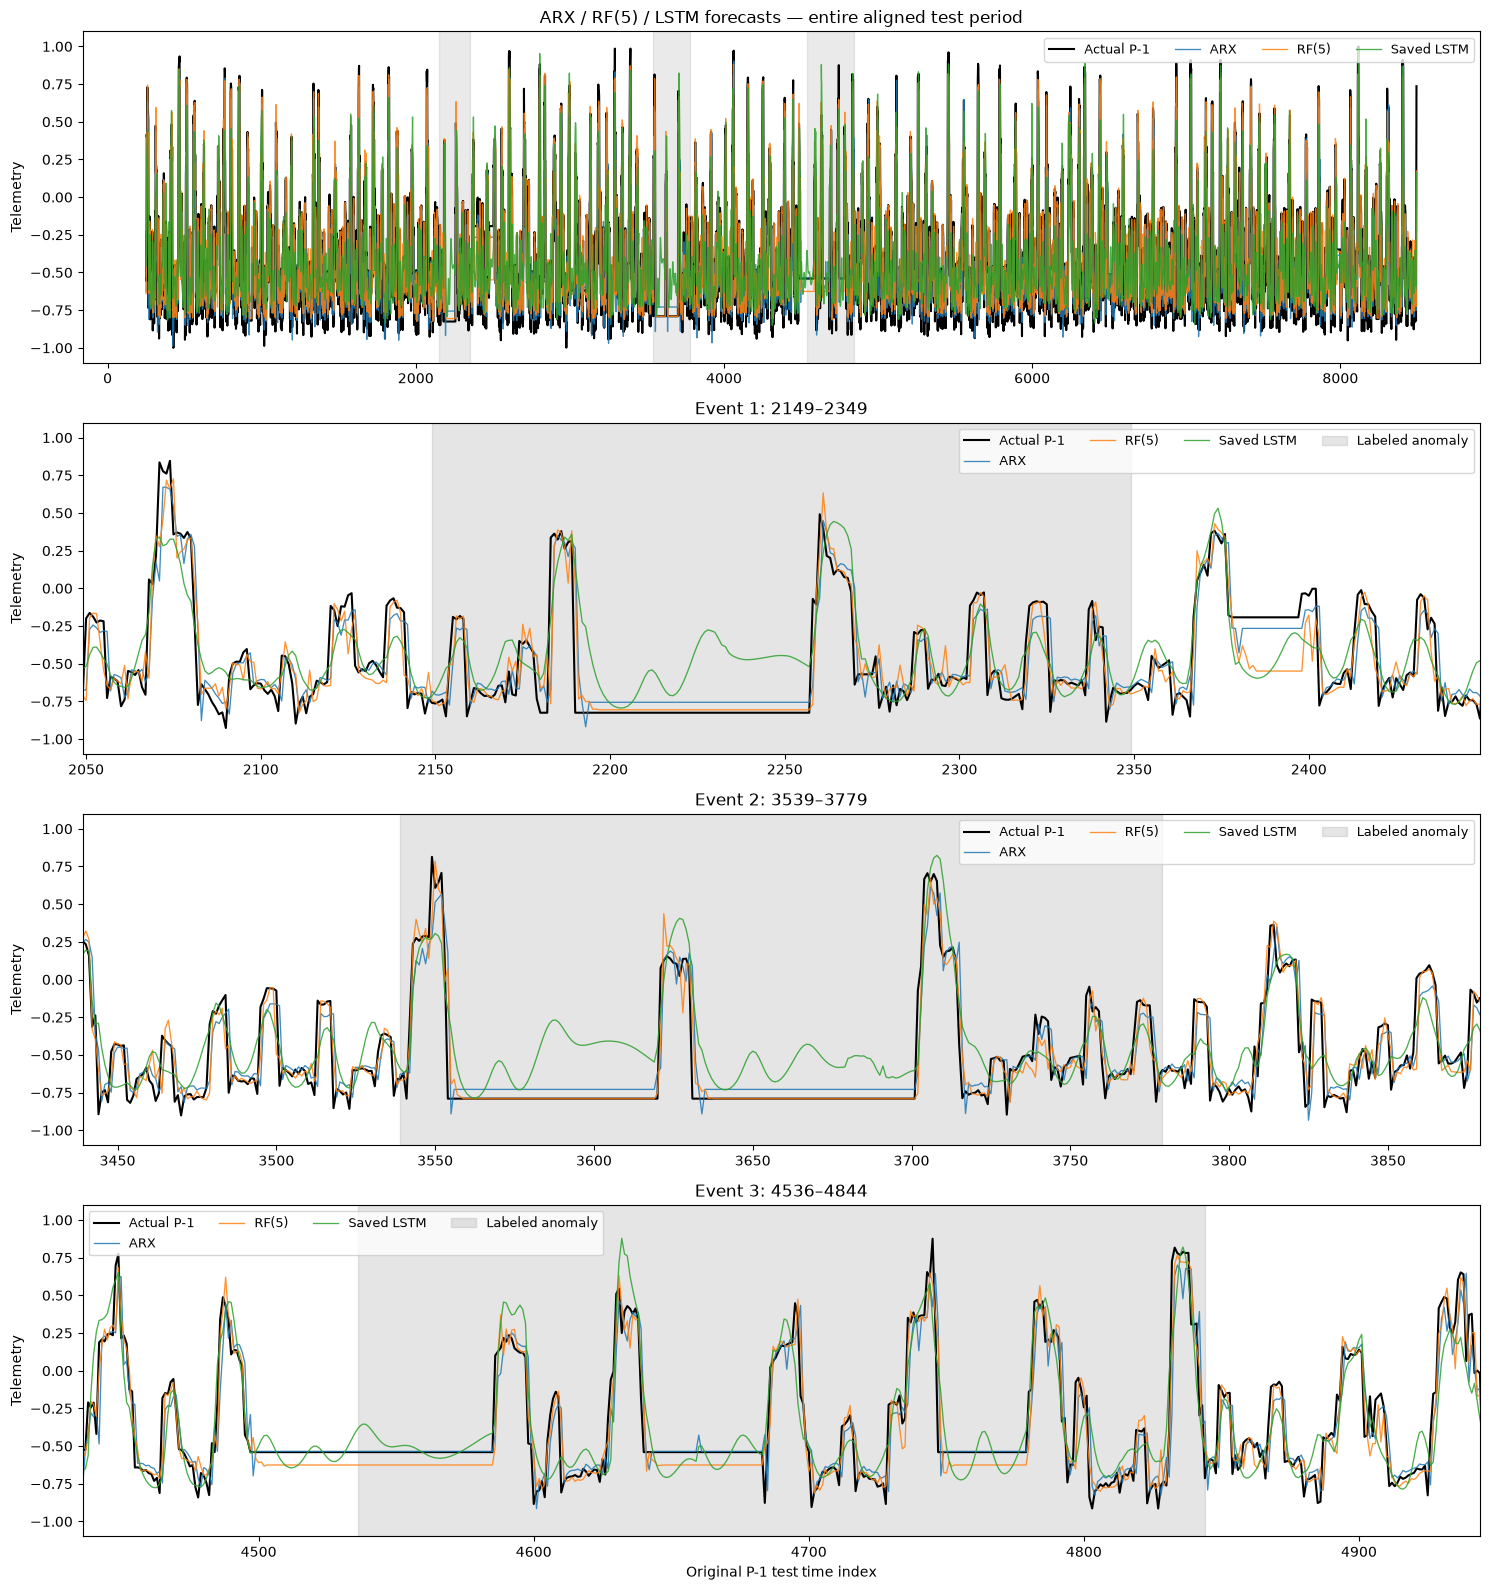

In [22]:
def compare_series(field, heading, ylabel, actual_curve=False):
    fig, axes = plt.subplots(1 + len(events), 1, figsize=(15, 4*(1+len(events))))
    for i, ax in enumerate(axes):
        if actual_curve: ax.plot(indices, actual, label="Actual P-1", color="black", linewidth=1.5)
        for name, result in models.items():
            ax.plot(indices, result[field], label=name, alpha=.85, linewidth=.95)
        if i == 0:
            for a,b in events: ax.axvspan(a,b, color="grey", alpha=.16)
            ax.set_title(heading + " — entire aligned test period")
        else:
            a,b = events[i-1]
            ax.axvspan(a,b,color="grey",alpha=.2,label="Labeled anomaly")
            ax.set_xlim(a-100,b+100)
            ax.set_title(f"Event {i}: {a}–{b}")
        ax.set_ylabel(ylabel)
        ax.legend(loc="best", ncol=4, fontsize=9)
    axes[-1].set_xlabel("Original P-1 test time index")
    plt.tight_layout()
    plt.show()

compare_series("predictions", "ARX / RF(5) / LSTM forecasts", "Telemetry", actual_curve=True)

## Raw absolute forecast errors, including event-level zooms

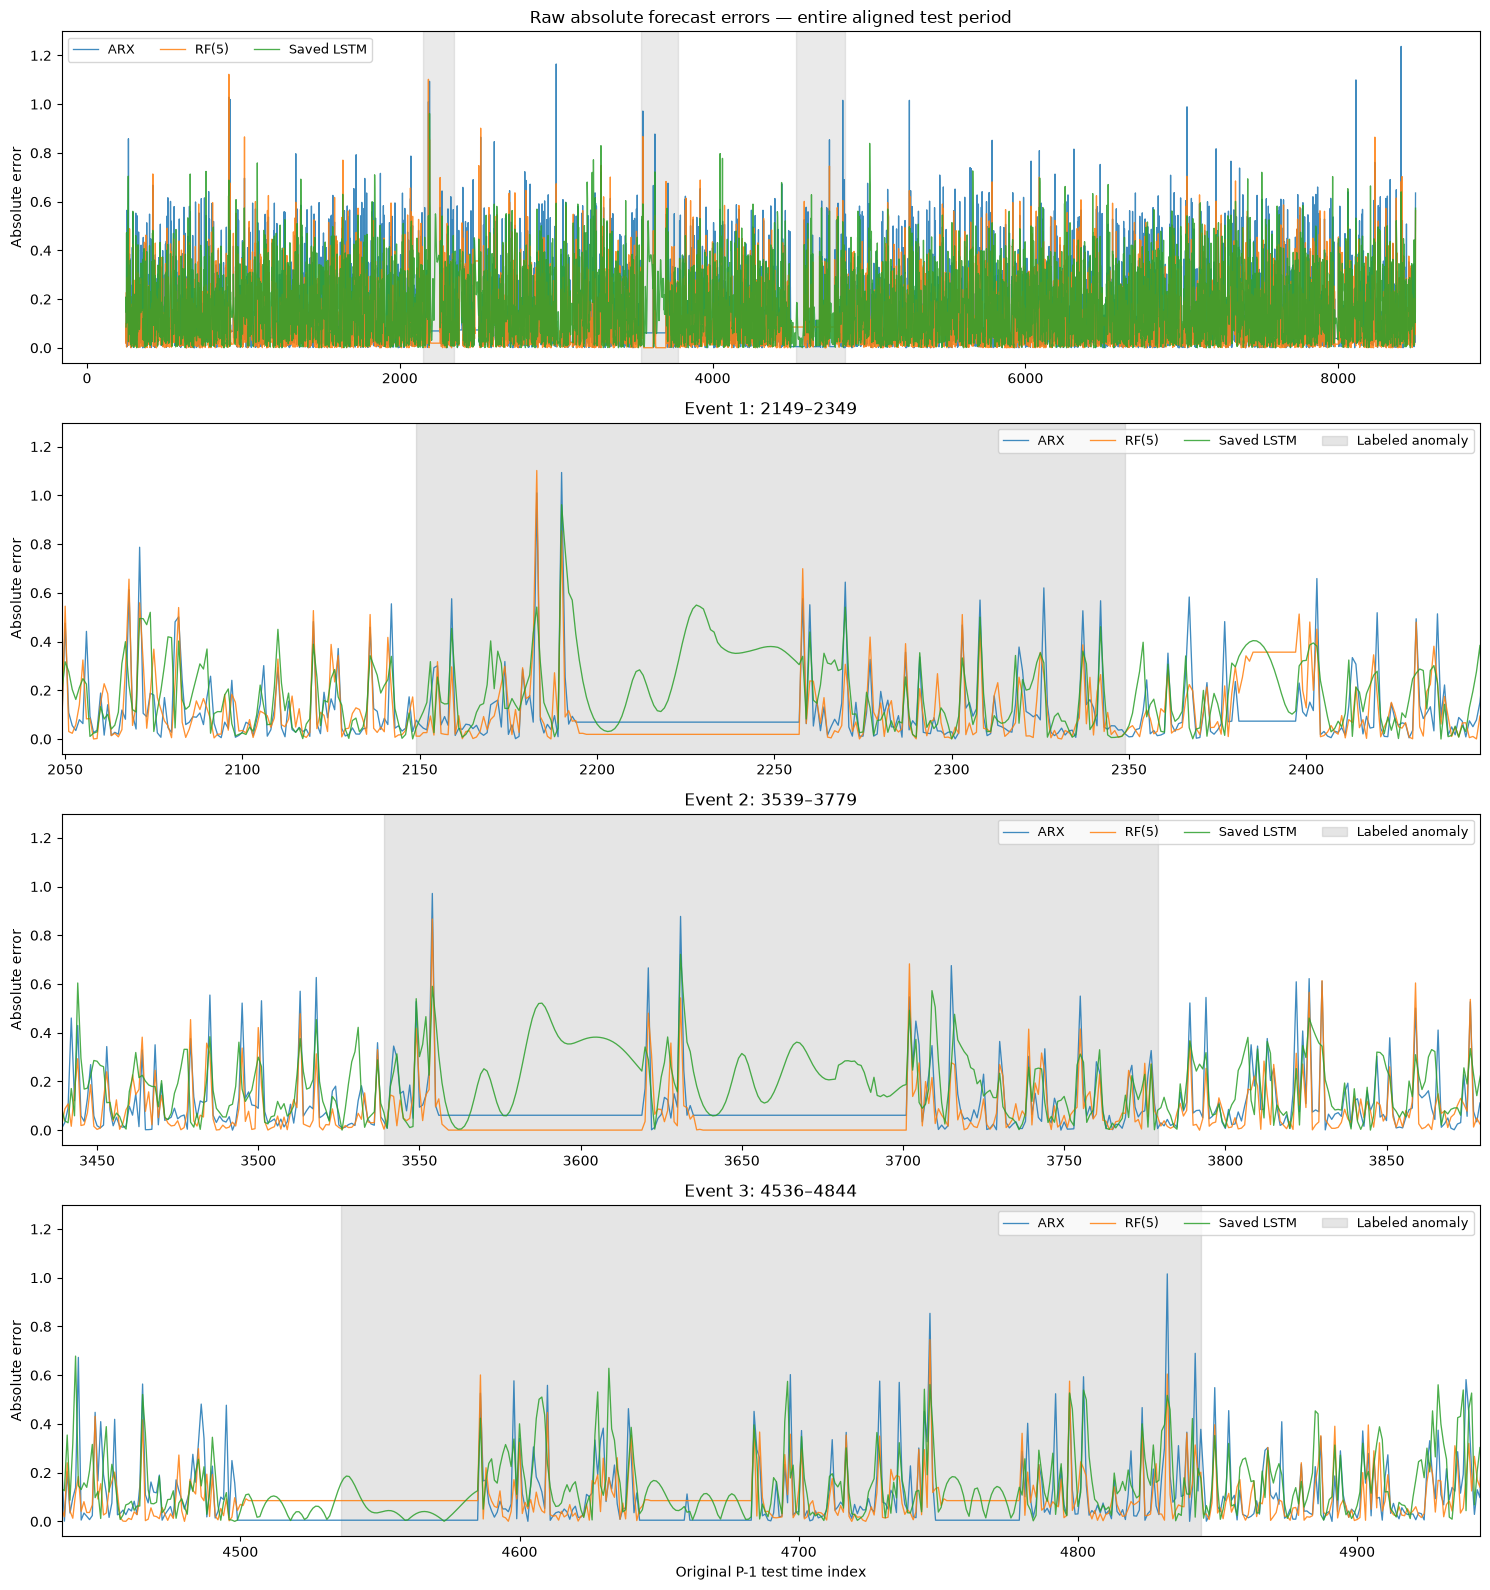

In [23]:
compare_series("raw_errors", "Raw absolute forecast errors", "Absolute error")

## Telemanom-smoothed errors, including event-level zooms
These traces are obtained from `detection.py`, so they match the actual detection pipeline. They are not separately recomputed with a potentially different EWMA definition.

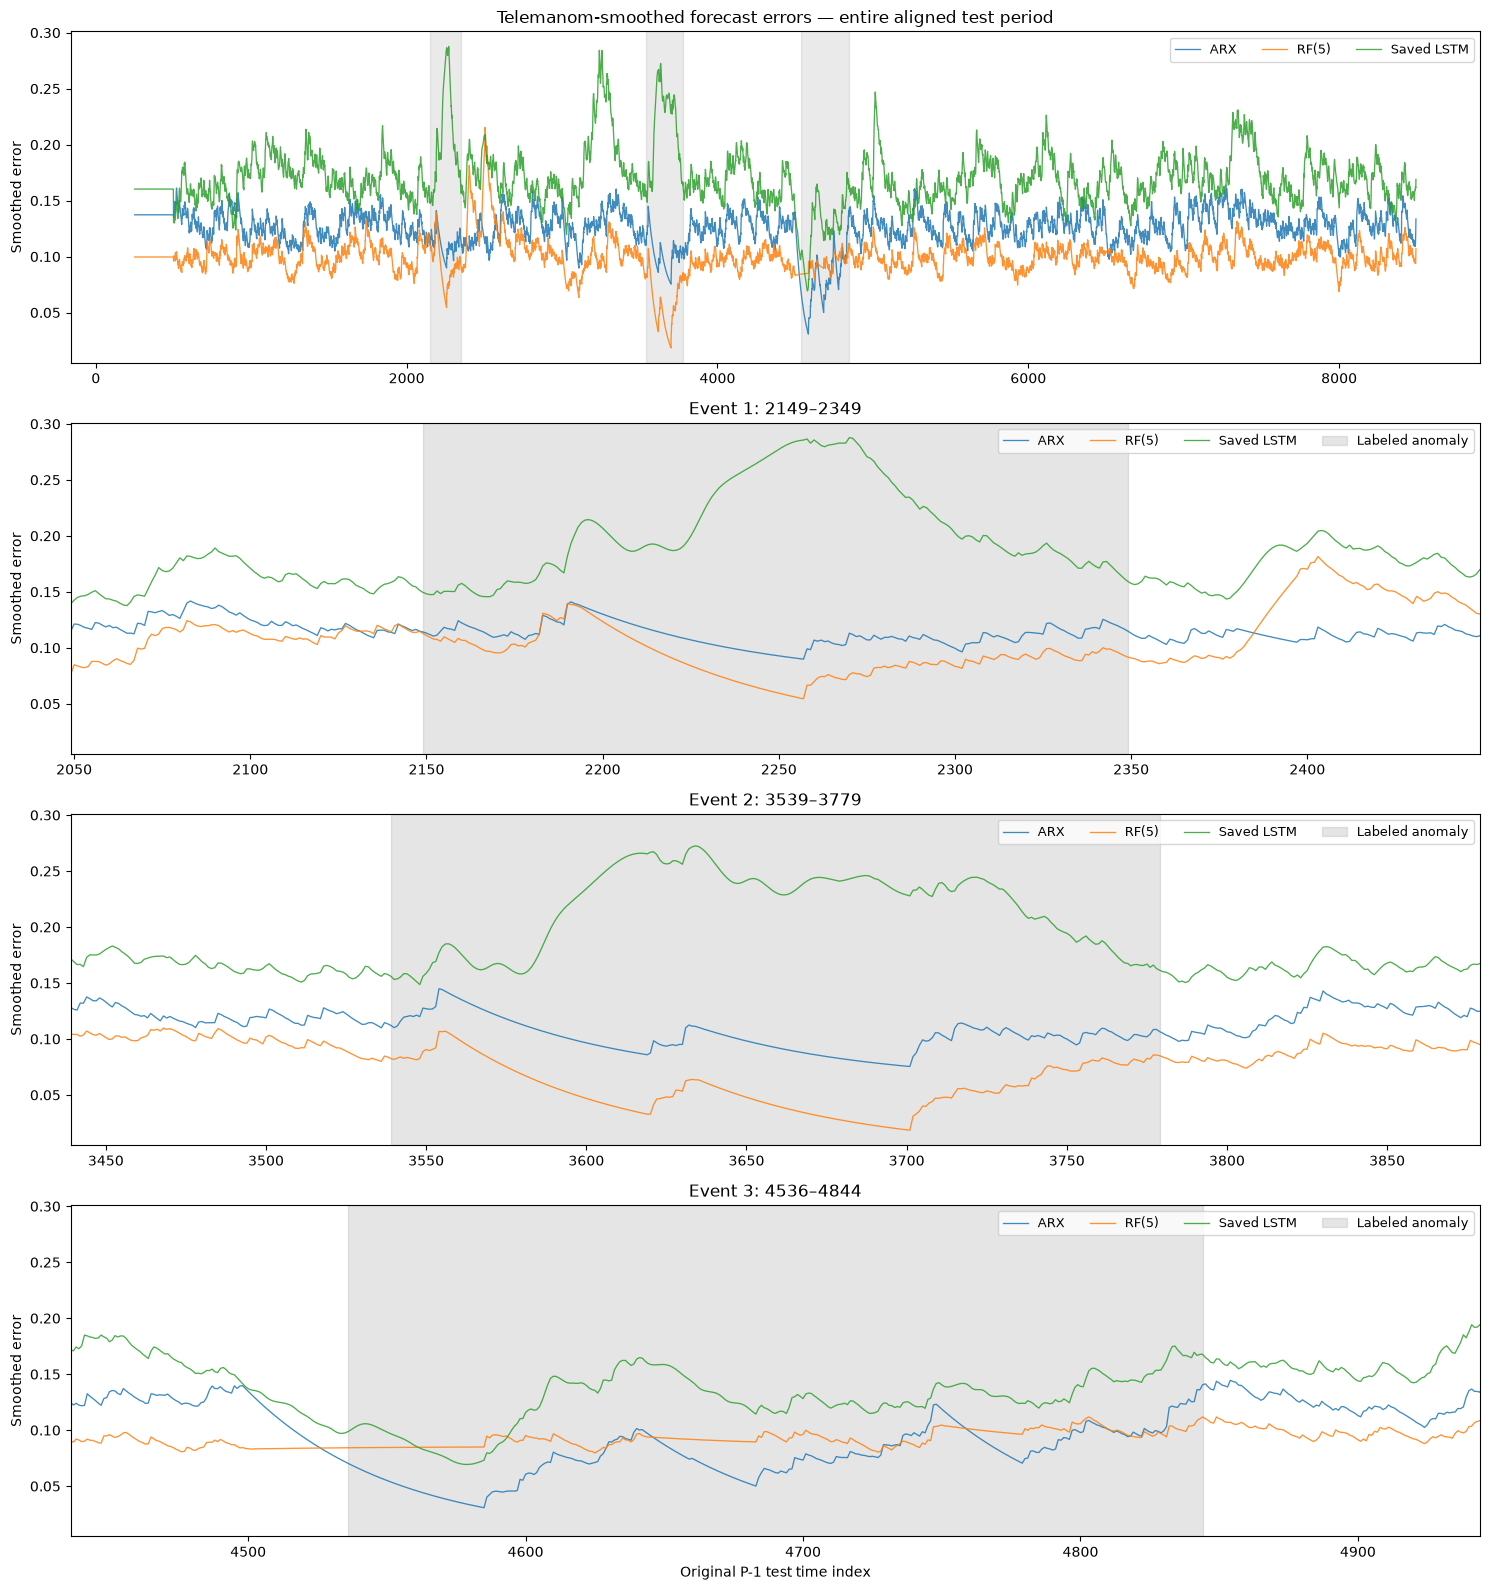

In [24]:
compare_series("smoothed_errors", "Telemanom-smoothed forecast errors", "Smoothed error")

## Event-level detection scores and detailed coverage table

In [25]:
evals = {name: detection.evaluate_event_detection(
    detected_intervals=result["detected_intervals"], labeled_intervals=events)
         for name,result in models.items()}
metrics = pd.DataFrame([
    {"Model": name, "Alert intervals": len(models[name]["detected_intervals"]),
     "TP": e["TP"], "FP": e["FP"], "FN": e["FN"],
     "Precision": e["precision"], "Recall": e["recall"], "F1": e["f1"]}
    for name,e in evals.items()
]).set_index("Model")
display(metrics)
metrics.to_csv(results_dir / "event_detection_metrics.csv")

coverage = pd.DataFrame({
    f"Event {i} ({a}–{b})": {
      name: "Detected" if any(s <= b and t >= a for s,t in r["detected_intervals"]) else "Missed"
      for name,r in models.items()}
    for i,(a,b) in enumerate(events, 1)
})
display(coverage)
coverage.to_csv(results_dir / "event_coverage.csv")

,Alert intervals,TP,FP,FN,Precision,Recall,F1
Model,,,,,,,
ARX,1,1,0,2,1.00,0.333333,0.500000
RF(5),2,2,0,1,1.00,0.666667,0.800000
Saved LSTM,4,3,1,0,0.75,1.000000,0.857143


,Event 1 (2149–2349),Event 2 (3539–3779),Event 3 (4536–4844)
ARX,Missed,Missed,Detected
RF(5),Detected,Detected,Missed
Saved LSTM,Detected,Detected,Detected


## Event detection heatmap

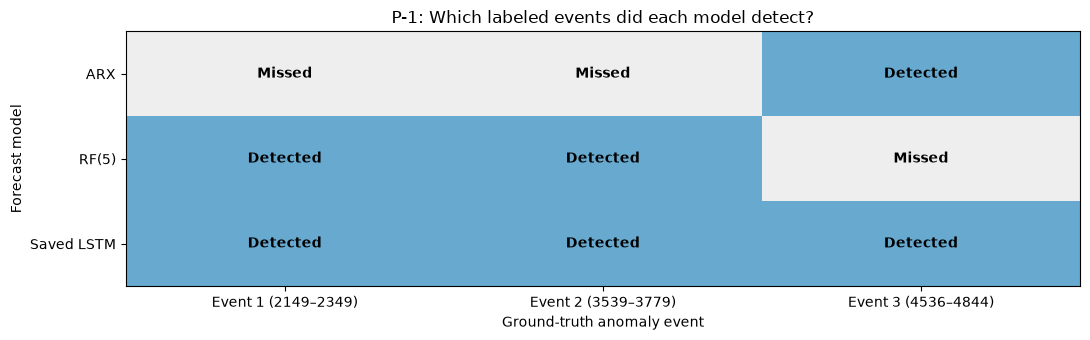

In [26]:
binary = (coverage == "Detected").astype(int)
fig, ax = plt.subplots(figsize=(11, 3.5))
from matplotlib.colors import ListedColormap
ax.imshow(binary.values, cmap=ListedColormap(["#eeeeee", "#67a9cf"]), vmin=0, vmax=1, aspect="auto")
ax.set_xticks(np.arange(binary.shape[1]), labels=binary.columns)
ax.set_yticks(np.arange(binary.shape[0]), labels=binary.index)
for i in range(binary.shape[0]):
    for j in range(binary.shape[1]):
        ax.text(j, i, coverage.iloc[i,j], ha="center", va="center", color="black", weight="bold")
ax.set_title("P-1: Which labeled events did each model detect?")
ax.set_xlabel("Ground-truth anomaly event")
ax.set_ylabel("Forecast model")
plt.tight_layout()
fig.savefig(results_dir / "event_detection_heatmap.png",dpi=200,bbox_inches="tight")
plt.show()

## Runtime comparison (ARX and RF only)
The separate modeling notebooks benchmark feature construction + forecasting, detection, and the complete pipeline using one numerical-library thread. For the fairest comparison, rerun both benchmarks on the same computer and software environment. The saved LSTM predictions cannot supply LSTM forecast-generation runtime.

,model,stage,calls per repeat,median ms,25th percentile ms,75th percentile ms,Model
0,ARX(1),Forecast generation,2000,0.149458,0.149000,0.149747,ARX
1,ARX(1),Detection only,5,53.850167,53.786646,53.957221,ARX
2,ARX(1),Complete pipeline,5,54.223308,54.208083,54.258533,ARX
3,RF(5),Forecast generation,5,79.410142,79.350908,79.486096,RF(5)
4,RF(5),Detection only,5,68.155583,68.105729,68.180496,RF(5)
5,RF(5),Complete pipeline,2,148.850480,148.799302,149.015541,RF(5)


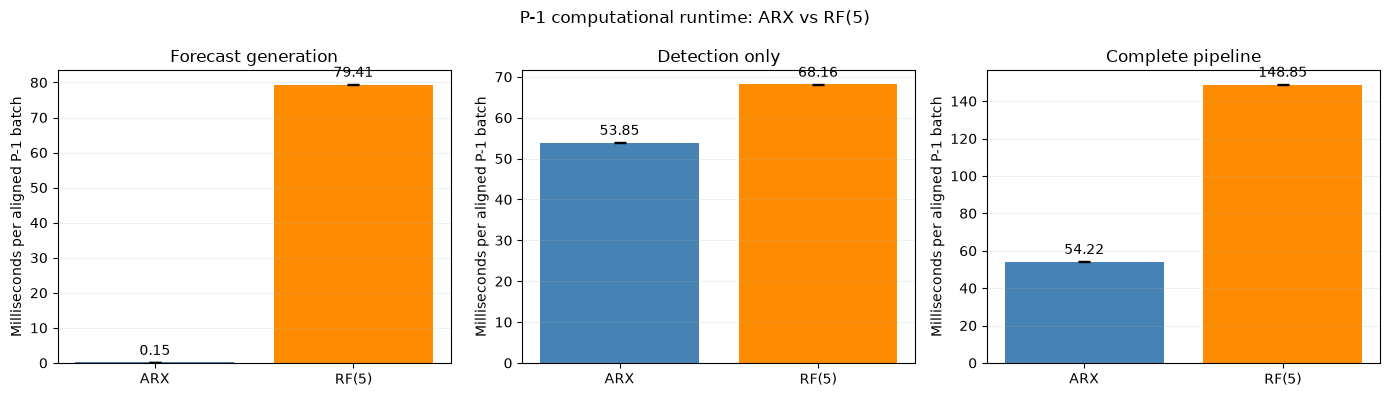

In [27]:
model_colors = {
    "ARX": "steelblue",
    "RF(5)": "darkorange"
}

runtime_frames = []
for kind in ("arx", "rf5"):
    path = results_dir / f"{kind}_runtime.csv"
    if not path.is_file(): raise FileNotFoundError(f"Run the {kind} benchmark and export: {path}")
    frame = pd.read_csv(path)
    frame["Model"] = "ARX" if kind == "arx" else "RF(5)"
    runtime_frames.append(frame)
runtimes = pd.concat(runtime_frames,ignore_index=True)
display(runtimes)
runtimes.to_csv(results_dir / "runtime_comparison.csv",index=False)

stages = ["Forecast generation", "Detection only", "Complete pipeline"]
fig, axes = plt.subplots(1, 3, figsize=(14,4))
for ax,stage in zip(axes, stages):
    subset = runtimes[runtimes["stage"] == stage].set_index("Model").reindex(["ARX", "RF(5)"])
    mid = subset["median ms"].to_numpy()
    lo = np.maximum(0, mid - subset["25th percentile ms"].to_numpy())
    hi = np.maximum(0, subset["75th percentile ms"].to_numpy() - mid)
    bars = ax.bar(
    subset.index,
    mid,
    yerr=np.vstack((lo, hi)),
    capsize=4,
    color=[model_colors[model] for model in subset.index]
)
    ax.bar_label(bars,fmt="%.2f",padding=3)
    ax.set_title(stage)
    ax.set_ylabel("Milliseconds per aligned P-1 batch")
    ax.grid(axis="y",alpha=.2)
fig.suptitle("P-1 computational runtime: ARX vs RF(5)")
plt.tight_layout()
fig.savefig(results_dir / "runtime_comparison.png",dpi=200,bbox_inches="tight")
plt.show()

## Illustrative monthly AWS Fargate cost comparison
Uses the cost calculations already performed in both modeling notebooks: 1 vCPU, 2 GB, 1,000 batches/day, 30 days, 30 startup seconds/day, 0.5× / 1× / 2× processing-time scenarios. These are **illustrative** estimates, not observed cloud bills, and exclude training and storage.

,Model,runtime multiplier,estimated monthly USD
0,ARX,0.5,0.02469
1,ARX,1.0,0.03497
2,ARX,2.0,0.05719
3,RF(5),0.5,0.04320
4,RF(5),1.0,0.07364
5,RF(5),2.0,0.13495


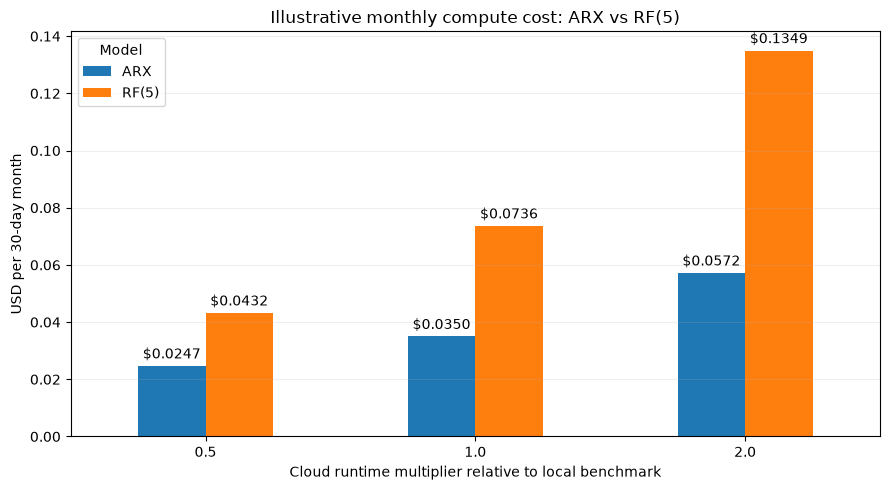

In [28]:
cost_frames = []
for kind in ("arx", "rf5"):
    frame = pd.read_csv(results_dir / f"{kind}_cost.csv")
    frame["Model"] = "ARX" if kind == "arx" else "RF(5)"
    cost_frames.append(frame)
costs = pd.concat(cost_frames,ignore_index=True)
display(costs[["Model", "runtime multiplier", "estimated monthly USD"]].round(5))
costs.to_csv(results_dir / "cost_comparison.csv",index=False)
pivot = costs.pivot(index="runtime multiplier",columns="Model",values="estimated monthly USD").reindex(columns=["ARX","RF(5)"])
ax = pivot.plot.bar(figsize=(9,5),rot=0)
for bars in ax.containers: ax.bar_label(bars,fmt="$%.4f",padding=3)
ax.set_title("Illustrative monthly compute cost: ARX vs RF(5)")
ax.set_xlabel("Cloud runtime multiplier relative to local benchmark")
ax.set_ylabel("USD per 30-day month")
ax.grid(axis="y",alpha=.2)
plt.tight_layout()
plt.savefig(results_dir / "monthly_cost_comparison.png",dpi=200,bbox_inches="tight")
plt.show()

## Interpretation guidance

- Accuracy (MAE/RMSE) and event detection are **different objectives**. Lower forecast error does not guarantee better anomaly detection.
- A true anomaly is counted as detected when **any predicted alert interval overlaps** its labeled interval. This is event-level, not pointwise, evaluation.
- Compare both number of labeled events recovered and false-positive alert intervals. Three labeled P-1 events alone cannot support broad claims about all telemetry channels.
- LSTM inference runtime would need to be measured to include LSTM in the runtime and cost plots.